# Key MRI Concepts and Equations

**Part:** Reference · **Reading time:** ~30 min (or dip in) · **Pass 1 overview:** [P1.1](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · [P1.2](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · [P1.3](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · [P1.4](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · [P1.5](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Complex numbers](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Fourier transform](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Spin statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)

This is a one-page summary of the whole course: the key ideas and equations of each topic, in the order of the book. Every equation is followed by a sentence **in words** and a list of its symbols with units, and every section links to the Pass-2 chapter(s) where it is derived. Use it to revise, or as a map when you get lost. All symbols follow [Notation and Symbols](Notation_and_Symbols.ipynb); numbers in brackets are typical values.

A few runnable cells evaluate the key formulas with realistic numbers — change the inputs and re-run.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Background material

* **Linear algebra, complex numbers, Fourier transforms** → [MRI Math Concepts](MRI_Math_Concepts.ipynb), [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [RM4](../refreshers/RM4_Fourier_Properties.ipynb), [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)
* **Signals and systems** — point spread functions, convolution → [RM4](../refreshers/RM4_Fourier_Properties.ipynb), [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)
* **Electricity and magnetism** — magnetic fields of currents, induction → [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb), [RP2](../refreshers/RP2_Induction_and_RF.ipynb), [RP3](../refreshers/RP3_Precession_and_Torque.ipynb)
* **ODEs** (for the Bloch equation and relaxation) → [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)

## 1. MR spin physics → [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb), [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [RP3](../refreshers/RP3_Precession_and_Torque.ipynb), [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)

**Resonance** — nuclear spins in a magnetic field precess at a frequency proportional to the field strength:

$$f = \bar{\gamma}\,\lVert\vec{B}\rVert, \qquad f_0=\bar\gamma B_0 .$$

In words: double the field, double the precession frequency; in the main field alone this is the Larmor frequency.
where $f$ = precession frequency [Hz]; $\bar\gamma=\gamma/2\pi$ = gyromagnetic ratio [Hz/T] (42.58 MHz/T for ¹H); $\lVert\vec B\rVert$ = magnitude of the magnetic field [T]; $B_0$ = main field [T]. (In angular units $\omega_0=\gamma B_0$ [rad/s].)

**Polarization — equilibrium magnetization** (corrected notation: the original wrote $I_Z$ and $k$):

$$M_0(\vec{r}) = \frac{N(\vec{r})\,\bar{\gamma}^2 h^2\, I(I+1)\, B_0}{3\, k_B T} = \frac{N(\vec r)\,\gamma^2\hbar^2\,I(I+1)\,B_0}{3k_BT}.$$

In words: the net magnetization at equilibrium grows with the number of spins and with $B_0$, and shrinks with temperature (thermal jiggling fights alignment). The two forms are identical because $\bar\gamma h=\gamma\hbar$.
where $M_0$ = equilibrium magnetization [A/m]; $N$ = spin density [m⁻³] ($6.7\times10^{28}$ for water ¹H); $h$, $\hbar=h/2\pi$ = Planck constant [J s]; $I$ = spin quantum number (1/2 for ¹H); $k_B$ = Boltzmann constant [J/K]; $T$ = absolute temperature [K] (310 K).

**Fractional polarization** (spin-½, small-exponent approximation):

$$P=\frac{N_\uparrow-N_\downarrow}{N_\uparrow+N_\downarrow}\approx\frac{h\bar\gamma B_0}{2k_BT}.$$

In words: only a tiny excess fraction (~10 ppm at 3 T) of spins sits in the lower-energy state; that excess is all the signal we get.
where $N_\uparrow, N_\downarrow$ = numbers of spins in the lower/upper energy state; $h\bar\gamma B_0=\Delta E$ = energy gap [J].

**Net magnetization at equilibrium** (lab frame = rotating frame for this vector, it lies on $z$):

$$\vec{M}(\vec{r},0) = \begin{bmatrix} 0 \\ 0 \\ M_0(\vec{r}) \end{bmatrix}.$$

In words: at rest, $\vec M$ points along $B_0$ and has no transverse part, so it does not precess and gives no signal.

**Excitation** — apply a (weak, µT) magnetic field $B_1$ rotating at the resonance frequency, perpendicular to $B_0$, to rotate $\vec M$ away from $z$. → [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb)

**The Bloch equation** (the master equation; derivation in [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)):

$$\frac{d\vec M}{dt}=\gamma\,\vec M\times\vec B-\frac{M_x\hat x+M_y\hat y}{T_2}-\frac{(M_z-M_0)\hat z}{T_1}.$$

In words: $\vec M$ precesses (clockwise) around $\vec B$, its transverse part decays with $T_2$ and its longitudinal part relaxes toward $M_0$ with $T_1$.
where $\gamma$ = gyromagnetic ratio [rad s⁻¹ T⁻¹]; $\times$ = cross product; $\hat x,\hat y,\hat z$ = unit vectors; $T_1, T_2$ = relaxation time constants [s].

**Relaxation** (solutions of the Bloch equation with no RF, in the rotating frame on resonance; ODE refresher: [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)):

$$M_{xy}(\vec{r},t) = M_{xy}(\vec{r},0)\, e^{-t/T_2(\vec{r})}$$

In words: transverse magnetization (the signal) decays exponentially with time constant $T_2$ — after one $T_2$ 37 % is left.

$$M_z(\vec{r},t) = M_z(\vec{r},0)\,e^{-t/T_1(\vec r)} + M_0(\vec{r})\left(1- e^{-t/T_1(\vec{r})}\right)$$

In words: longitudinal magnetization forgets its starting value and recovers toward $M_0$ with time constant $T_1$ — after one $T_1$ it has covered 63 % of the way.
where $M_{xy}=M_x+iM_y$ = transverse magnetization (complex) [A/m]; $M_z$ = longitudinal magnetization [A/m]; $T_1$ = longitudinal relaxation time [s] (0.25–4 s); $T_2$ = transverse relaxation time [s] (10 ms – 2 s); $T_2\le T_1$ always.

> **⚠️ Common confusion:** $T_1$ and $T_2$ are **time constants** (seconds), not rates. The corresponding rates are $R_1=1/T_1$, $R_2=1/T_2$ [s⁻¹].

The next cell evaluates the Larmor frequency, the energy gap, the polarization and $M_0$ for water protons at body temperature for several field strengths (all SI units).

In [2]:
T_body = 310.0                       # body temperature [K]
N_water = 2 * 55.5e3 * mt.AVOGADRO   # 1H per m^3 in water: 2 H per molecule, 55.5 mol/L = 55.5e3 mol/m^3
I_spin = 0.5                         # spin quantum number of 1H

print(f"{'B0 [T]':>6} | {'f0 [MHz]':>9} | {'Delta E [J]':>11} | {'polarization [ppm]':>18} | {'M0 [A/m]':>9} | {'mu0*M0 [nT]':>11}")
for B0 in [0.55, 1.5, 3.0, 7.0]:
    f0 = mt.larmor_frequency(B0)                                     # [Hz]
    dE = mt.H_PLANCK * f0                                            # [J]
    P = dE / (2 * mt.K_BOLTZMANN * T_body)                           # fractional polarization [-]
    M0 = N_water * mt.GAMMA**2 * mt.HBAR**2 * I_spin * (I_spin + 1) * B0 / (3 * mt.K_BOLTZMANN * T_body)  # [A/m]
    print(f"{B0:6.2f} | {f0/1e6:9.2f} | {dE:11.3e} | {P*1e6:18.2f} | {M0:9.2e} | {mt.MU0*M0*1e9:11.2f}")

B0 [T] |  f0 [MHz] | Delta E [J] | polarization [ppm] |  M0 [A/m] | mu0*M0 [nT]
  0.55 |     23.42 |   1.552e-26 |               1.81 |  1.71e-03 |        2.15
  1.50 |     63.87 |   4.232e-26 |               4.94 |  4.66e-03 |        5.86
  3.00 |    127.73 |   8.464e-26 |               9.89 |  9.32e-03 |       11.72
  7.00 |    298.04 |   1.975e-25 |              23.07 |  2.18e-02 |       27.34


Interpretation: at 3 T only ~10 in a million protons contribute net magnetization, and the resulting field $\mu_0M_0$ is about 10 nT — a hundred-millionth of $B_0$. That is why MRI is a low-SNR technique and why higher fields help.

## 2. MRI system → [B1](../pass2_deep_dive/B1_MRI_System.ipynb), [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb), [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb), [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb), [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)

1. **Main magnet — $B_0$** [0.55–7 T, static, along $z$]: polarization. Usually a superconducting solenoid in liquid helium. → [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)
2. **Radiofrequency (RF) coils**
    * transmit RF coil — $B_1^+(\vec{r},t)$ [~10 µT at ~64–300 MHz]: provides homogeneous excitation;
    * receive RF coil — $B_1^-(\vec{r},t)$: detects the signal with high sensitivity (arrays of small elements). → [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)
3. **Magnetic field gradient coils — $\vec{G}(t)$** [up to 40–80 mT/m, switched in ~0.2 ms]: spatial encoding, $B_z(\vec r,t)=B_0+\vec G(t)\cdot\vec r$. → [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)

Intuition for magnetic fields and sensitivity profiles of loop coils: [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb), [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb).

> **🔧 Engineering reality:** each of these is an engineering extreme — a magnet storing MJ of energy at 4 K, gradient amplifiers delivering ~900 A at ~2 kV with sub-millisecond switching, RF amplifiers of ~30 kW peak, and receivers that detect nV-level signals. See [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)–[B6](../pass2_deep_dive/B6_MRI_Safety.ipynb).

## 3. MRI experiment → [B1](../pass2_deep_dive/B1_MRI_System.ipynb), [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb)

1. Polarization ($B_0$)
2. Excitation ($B_1^+$)
3. Signal acquisition ($B_1^-$)
* Gradients during excitation and acquisition for spatial encoding
* Repeat excitation and acquisition as needed

The experiment is described by a **pulse sequence** (timing diagram of RF, $G_x$, $G_y$, $G_z$ and DAQ). → [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb)

## 4. MR contrasts → [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb), [D4](../pass2_deep_dive/D4_Image_Contrast_Examples.ipynb)

Contrast weightings (for spin echo; with gradient echo replace $T_2$ by $T_2^*$):

| Weighting | TE | TR | Why |
|---|---|---|---|
| $T_1$-weighted | short | short | short TR leaves tissues with long $T_1$ un-recovered (dark); short TE avoids $T_2$ effects |
| $T_2$-weighted | long | long | long TR removes $T_1$ differences; long TE lets short-$T_2$ tissue decay (dark) |
| Proton density (PD)-weighted | short | long | removes both $T_1$ and $T_2$ effects, leaving $M_0$ |

**Spin echo** (90°, TE ≪ TR):

$$S_{SE} \propto M_0\left(1-e^{-TR/T_1}\right)e^{-TE/T_2}.$$

In words: the first factor is how much $M_z$ has recovered before each excitation ($T_1$ weighting via TR), the second how much $M_{xy}$ has decayed by the echo ($T_2$ weighting via TE).
where $S$ = signal [a.u.]; $TR$ = repetition time [s]; $TE$ = echo time [s].

**Spoiled gradient echo** (steady state; corrected: the original wrote $T_2$ instead of $T_2^*$ here):

$$S_{SPGR} \propto M_0 \sin\theta\, e^{-TE/T_2^*}\,\frac{1- e^{-TR/T_1}}{1- \cos\theta\, e^{-TR/T_1}}.$$

In words: each TR a fraction $\sin\theta$ of the available $M_z$ becomes signal, but larger flip angles leave less $M_z$ for the next TR; the fraction balances out to a steady state.
where $\theta$ = flip angle [rad]; $T_2^*$ = effective transverse relaxation time [s]; $E_1=e^{-TR/T_1}$ is a common shorthand.

**Ernst angle** — the flip angle that maximizes the spoiled-GRE signal:

$$\theta_E = \arccos\!\left(e^{-TR/T_1}\right).$$

In words: the shorter TR is compared with $T_1$, the smaller the optimal flip angle.

**Inversion recovery** (180° – TI – 90° readout, TE ≪ TR):

$$S_{IR} \propto M_0\,e^{-TE/T_2}\left(1 - 2e^{-TI/T_1} + e^{-TR/T_1}\right).$$

In words: after inversion, $M_z$ recovers from $-M_0$; at $TI\approx T_1\ln 2$ (if $TR\gg T_1$) it crosses zero and that tissue is **nulled** (FLAIR nulls CSF, STIR nulls fat).
where $TI$ = inversion time [s]. The signal can be negative (sign is lost in magnitude images).

**Magnetization preparation** (inversion, saturation, $T_2$-prep, fat-sat) encodes extra contrast in $M_z$ before a fast readout. → [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)

The next cell plots the spoiled-GRE signal versus flip angle for white matter and CSF at a short TR, and marks the Ernst angle computed with `mt.ernst_angle`.

white matter (T1=0.83 s)  : Ernst angle =   8.9 deg, max signal = 0.073 M0
CSF (T1=4 s)              : Ernst angle =   4.0 deg, max signal = 0.035 M0


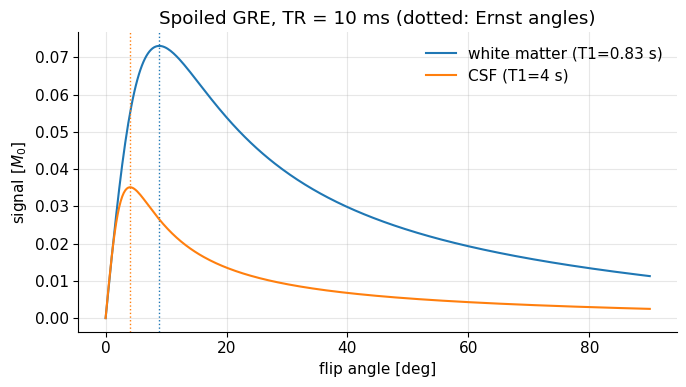

In [3]:
TR, TE = 10e-3, 3e-3                                 # [s]
tissues = {"white matter (T1=0.83 s)": (0.83, 0.05), "CSF (T1=4 s)": (4.0, 0.5)}   # (T1, T2*) [s] at 3 T
flip = np.deg2rad(np.linspace(0, 90, 361))           # [rad]

plt.figure(figsize=(7, 4))
for name, (T1, T2s) in tissues.items():
    S = mt.spoiled_gre_signal(flip, TE, TR, T1, T2s)
    thE = mt.ernst_angle(TR, T1)
    line, = plt.plot(np.rad2deg(flip), S, label=name)
    plt.axvline(np.rad2deg(thE), color=line.get_color(), ls=":", lw=1)
    print(f"{name:26s}: Ernst angle = {np.rad2deg(thE):5.1f} deg, max signal = {S.max():.3f} M0")
plt.xlabel("flip angle [deg]"); plt.ylabel(r"signal [$M_0$]")
plt.title(f"Spoiled GRE, TR = {TR*1e3:.0f} ms (dotted: Ernst angles)")
plt.legend(); plt.tight_layout(); plt.show()

Interpretation: at TR = 10 ms the Ernst angle is ≈ 9° for white matter and ≈ 4° for CSF; at larger flip angles (e.g. 30°) short-$T_1$ white matter is much brighter than CSF — that is $T_1$ weighting.

## 5. In vivo spin physics → [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb)

**Magnetic susceptibility** ($\chi$, dimensionless)
* an inherent property of materials: how strongly they magnetize in a field (diamagnetic $\chi<0$: water, tissue; paramagnetic $\chi>0$: O₂, deoxyhaemoglobin, Gd; ferromagnetic $\chi\gg0$: iron, steel);
* differences in susceptibility distort the magnetic field, especially at boundaries;
* in vivo sources: iron, oxygenated vs deoxygenated blood, air–tissue interfaces, implants.

**Chemical shift**
* the chemical environment (electron cloud) of a nucleus shields it from $B_0$: $B_{eff}=B_0(1-\sigma)$;
* in vivo: "fat" is modelled as a single peak at $\delta_{cs}\approx-3.5$ ppm from water protons.

$$\Delta f_{cs} = \delta_{cs}\,\bar\gamma B_0 .$$

In words: a fixed relative shift (ppm) becomes a frequency shift that grows with field strength.
where $\Delta f_{cs}$ = chemical-shift frequency offset [Hz] (fat: −224 Hz at 1.5 T, −447 Hz at 3 T); $\delta_{cs}$ = chemical shift [ppm = 10⁻⁶]; $\sigma$ = shielding constant [–].

**Total $z$-field** seen by a spin:

$$B_z(\vec r)=B_0+\Delta B_0(\vec r)+\delta_{cs}B_0\;(+\,\vec G\cdot\vec r).$$

In words: main field + imperfections/susceptibility + chemical shift (+ gradients when on). $\Delta B_0$ is < 1 ppm from the magnet, up to ~10 ppm near air.

## 6. In vivo contrasts → [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)

**Phase** — chemical shift and off-resonance ($\Delta f_r=\bar\gamma\Delta B_0$) create phase differences in $M_{xy}$ and in the signal: $\phi = -2\pi\Delta f\,TE$ (our clockwise convention).

**$T_2^*$**

$$\frac{1}{T_2^*}=\frac{1}{T_2}+\frac{1}{T_2'} .$$

In words: the observed decay rate is the irreversible $T_2$ rate plus an extra rate from field inhomogeneity within the voxel.
where $T_2'$ = inhomogeneity dephasing time [s]. Facts: intra-voxel dephasing due to field inhomogeneity; largely driven by magnetic susceptibility; eliminated (refocused) by a spin echo; creates susceptibility contrast (BOLD, iron, haemorrhage).

**Fat**
* fat/water (Dixon) imaging — separate fat and water using images at multiple echo times (in-phase $TE=n/|\Delta f_{cs}|$, out-of-phase $TE=(n+\frac12)/|\Delta f_{cs}|$);
* fat suppression — spectrally selective RF pulses and/or inversion recovery (STIR).

**Contrast agents** (relaxivity model):

$$\frac{1}{\hat T_{1}}=\frac{1}{T_{1}}+r_{1}[CM],\qquad \frac{1}{\hat T_{2}}=\frac{1}{T_{2}}+r_{2}[CM].$$

In words: the agent adds to the relaxation *rates* in proportion to its concentration.
where $\hat T_{1,2}$ = relaxation times with agent [s]; $r_{1,2}$ = relaxivities [mM⁻¹ s⁻¹]; $[CM]$ = concentration [mM].
* Gadolinium (Gd)-based agents — most common, primarily shorten $T_1$ (bright on $T_1$w).
* Iron-oxide agents — less common; primarily shorten $T_2$ and $T_2^*$ (dark), with a smaller $T_1$ effect. *(Corrected: the original said they mainly shorten $T_1$.)*

## 7. RF pulses → [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb), [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb), [E3](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)

**Flip angle**

$$\theta = \gamma \int_0^{T_{rf}} \lvert b_1(\tau)\rvert\, d\tau .$$

In words: the tip angle is the area under the RF amplitude envelope times $\gamma$ (for a hard pulse simply $\theta=\gamma B_{1,0}T_{rf}$).
where $\theta$ [rad]; $b_1(t)$ = complex RF envelope [T]; $T_{rf}$ = pulse duration [s]; $\tau$ = integration variable [s]; $\gamma$ [rad s⁻¹ T⁻¹] (note: $\gamma$, not $\bar\gamma$, because the result is in radians).

**Time–bandwidth product** — constant for a given pulse shape:

$$TBW = T_{rf}\cdot BW_{rf}.$$

In words: making a pulse shorter makes its frequency band wider in proportion (a Fourier property).
where $BW_{rf}$ = pulse bandwidth [Hz]; $TBW$ [–] (2–12).

**SAR** (per pulse):

$$SAR \propto B_0^2\int_0^{T_{rf}} \lvert b_1(\tau)\rvert^2 d\tau .$$

In words: RF heating grows with the *square* of the RF amplitude (double the flip angle in the same time → 4× SAR) and roughly with $B_0^2$.
where $SAR$ = specific absorption rate [W/kg] (averaged over time and tissue mass).

**Pulse profile** — the flip angle (or $M_{xy}$) as a function of frequency/position. For small flip angles (small-tip approximation, best below ~30° but qualitatively useful up to 90°) it is approximately proportional to the Fourier transform of the pulse envelope. → [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb), [E3](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)

**Slice selection** — slice thickness:

$$\Delta z = \frac{BW_{rf}}{\bar{\gamma}\, G_{z,SS}} .$$

In words: the gradient spreads frequencies over space; the slice is the region whose frequencies fall inside the pulse bandwidth. Thinner slices need a narrower bandwidth or a stronger gradient.
where $\Delta z$ = slice thickness [m]; $G_{z,SS}$ = slice-select gradient [T/m].

**Slice shifting**

$$f_{off} = \bar{\gamma}\, G_{z,SS}\, z_{off} .$$

In words: to move the slice by $z_{off}$, shift the RF frequency by the Larmor-frequency change at that position.
where $f_{off}$ = RF frequency offset [Hz]; $z_{off}$ = slice offset [m].

In [4]:
# Slice thickness and slice offset for a typical slice-selective sinc pulse
TBW = 4.0                 # time-bandwidth product [-]
T_rf = 2e-3               # pulse duration [s]
G_ss = 10e-3              # slice-select gradient: 10 mT/m [T/m]
z_off = 0.03              # 3 cm off-centre [m]

BW_rf = TBW / T_rf                                    # [Hz]
dz = BW_rf / (mt.GAMMA_BAR * G_ss)                    # [m]
f_off = mt.GAMMA_BAR * G_ss * z_off                   # [Hz]
theta = np.pi / 2
B1_hard = mt.b1_for_flip(theta, T_rf)                 # amplitude of a *hard* 90 deg pulse of same length [T]
print(f"BW_rf = {BW_rf:.0f} Hz -> slice thickness = {dz*1e3:.2f} mm; offset of {z_off*1e2:.0f} cm needs f_off = {f_off/1e3:.2f} kHz")
print(f"(for comparison, a hard 90-degree pulse of {T_rf*1e3:.0f} ms needs B1 = {B1_hard*1e6:.2f} uT)")

BW_rf = 2000 Hz -> slice thickness = 4.70 mm; offset of 3 cm needs f_off = 12.77 kHz
(for comparison, a hard 90-degree pulse of 2 ms needs B1 = 2.94 uT)


Interpretation: a 2 ms pulse with TBW 4 (2 kHz bandwidth) and a 10 mT/m gradient selects a ≈ 4.7 mm slice; moving it 3 cm requires a ≈ 12.8 kHz frequency offset — tiny compared with the 128 MHz carrier.

## 8. Spatial encoding → [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [F2](../pass2_deep_dive/F2_K-space.ipynb), [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)

**Frequency encoding** — a gradient during data acquisition maps frequency to position:

$$x = \frac{f}{\bar\gamma\, G_{x,r}} .$$

In words: with the readout gradient on, each position $x$ precesses at its own frequency, so a frequency analysis (FT) of the signal gives the object's profile along $x$.
where $f$ = frequency relative to the centre frequency [Hz]; $G_{x,r}$ (= $G_{xr}$) = readout gradient [T/m]; $x$ [m].

**Phase encoding** — a gradient pulse before readout, stepped for $n = 1, \ldots, N_{PE}$:

$$\Phi(n) = \gamma\left(-G_{y,PE} + (n-1)\, G_{yi}\right) t_y\, y .$$

In words: each repetition gives the magnetization at height $y$ a phase proportional to $y$ and to the (stepped) gradient area; together the steps sample $k_y$.
where $\Phi(n)$ = phase [rad]; $G_{y,PE}$ (= $G_{yp}$) = maximum phase-encode amplitude [T/m]; $G_{yi}$ = increment [T/m], with $2G_{y,PE}=(N_{PE}-1)G_{yi}$; $t_y$ = phase-encode duration [s]; $y$ = position [m]. (Sign: with our clockwise convention the phase is $-\Phi(n)$; only the magnitude of the encoding matters here.)

**k-space** — spatial encoding is defined by the running area under the gradients since excitation:

$$\vec{k}(t) = \bar\gamma \int_0^t \vec{G}(\tau)\, d\tau .$$

In words: k is the scaled gradient area; it tells which spatial frequency of the object the signal at time $t$ measures. (The original writes $\frac{\gamma}{2\pi}\int$, which is identical.)
where $\vec k$ = k-space position [m⁻¹ = cycles/m]; $\vec G$ = gradient [T/m].

**Signal equation** — it turns image reconstruction into an inverse Fourier transform:

$$s(t) = \int m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r=\mathcal{F}\{m(\vec{r})\}\big|_{\vec{k} = \vec{k}(t)} = M(\vec{k}(t)).$$

In words: the demodulated signal at time $t$ equals the Fourier transform of the image evaluated at the current k-space position.
where $s(t)$ = received signal [a.u.]; $m(\vec r)=M_{xy}(\vec r,TE)$ = the image [a.u.]; $M(\vec k)$ = k-space data (not the magnetization!); $\mathcal F$ = Fourier transform.
* describes all MRI acquisitions, including frequency and phase encoding;
* effects of gradients can be refocused (net area zero → back to $\vec k=0$);
* supports 2D and 3D imaging.

## 9. Image characteristics → [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb), [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb)

$$FOV = \frac{1}{\Delta k} \qquad\qquad \delta = \frac{1}{2 k_{max}}$$

In words: the spacing between k-space samples sets how big the image can be before it wraps (FOV); how far out you sample sets the pixel size (resolution).
where $\Delta k$ = sample spacing [m⁻¹]; $k_{max}$ = maximum k sampled [m⁻¹]; $FOV$ [m]; $\delta$ = resolution / pixel size [m]. For Cartesian readout: $FOV_x=1/(\bar\gamma G_{x,r}\Delta t)$ and $\delta_x=1/(\bar\gamma G_{x,r}T_{read})$.

**SNR**

$$SNR \propto f_{seq}\cdot \mathrm{Voxel\ Volume}\cdot\sqrt{T_{meas}} .$$

In words: SNR is proportional to how much magnetization the sequence leaves (contrast factor), linearly to voxel volume, and to the square root of the total time spent sampling.
where $f_{seq}$ = sequence/tissue factor (e.g. the spoiled-GRE formula) [–]; Voxel Volume $=\delta_x\delta_y\delta_z$ [m³]; $T_{meas}=N_{TR}T_{read}$ = total ADC sampling time [s].

**Scan time**

$$T_{scan} = TR \cdot N_{TR}, \qquad N_{TR}=\frac{N_{PE,total}\cdot NEX}{ETL \cdot R}.$$

In words: scan time is TR times the number of repetitions; echo trains (ETL) and undersampling (R) reduce the repetitions needed, averaging (NEX) increases them.
where $N_{TR}$ = number of TR periods; $N_{PE,total}$ = total phase-encode lines (product of both PE dimensions in 3D); $NEX$ = averages; $ETL$ = echo train length; $R$ = acceleration factor. (The original wrote $T_{scan}=TR\cdot N_{TR}\cdot NEX$ *and* $N_{TR}$ without NEX; NEX must be counted once.)

In [5]:
# From sequence parameters to FOV, resolution, scan time and relative SNR (2D Cartesian gradient echo)
G_read = 8e-3            # readout gradient: 8 mT/m [T/m]
dwell = 10e-6            # dwell time Delta t [s]  -> BW_read = 100 kHz
N_read, N_PE = 256, 256  # readout samples, phase encodes
TR, NEX, ETL, R = 50e-3, 1, 1, 1
slice_thk = 5e-3         # [m]

BW_read = 1 / dwell                                   # [Hz]
FOV_x = 1 / (mt.GAMMA_BAR * G_read * dwell)           # [m]
T_read = N_read * dwell                               # [s]
delta_x = 1 / (mt.GAMMA_BAR * G_read * T_read)        # [m]  (= FOV_x / N_read)
N_TR = N_PE * NEX / (ETL * R)
T_scan = TR * N_TR                                    # [s]
T_meas = N_TR * T_read                                # [s]
voxel = delta_x * delta_x * slice_thk                 # [m^3], square pixels assumed
print(f"BW_read = {BW_read/1e3:.0f} kHz ({BW_read/N_read:.0f} Hz/pixel), FOV_x = {FOV_x*1e2:.1f} cm, "
      f"pixel = {delta_x*1e3:.2f} mm, T_read = {T_read*1e3:.2f} ms")
print(f"N_TR = {N_TR:.0f}, scan time = {T_scan:.1f} s, ADC time T_meas = {T_meas:.2f} s")

# relative SNR change if we halve the bandwidth (longer readout) or use R = 2 parallel imaging with g = 1.2
snr = lambda vox, tmeas, g=1.0: vox * np.sqrt(tmeas) / g
ref = snr(voxel, T_meas)
print(f"half the bandwidth: SNR x {snr(voxel, 2*T_meas)/ref:.2f};  R = 2, g = 1.2: SNR x {snr(voxel, T_meas/2, 1.2)/ref:.2f}")

BW_read = 100 kHz (391 Hz/pixel), FOV_x = 29.4 cm, pixel = 1.15 mm, T_read = 2.56 ms
N_TR = 256, scan time = 12.8 s, ADC time T_meas = 0.66 s
half the bandwidth: SNR x 1.41;  R = 2, g = 1.2: SNR x 0.59


Interpretation: 8 mT/m with 10 µs dwell gives ≈ 29 cm FOV and ≈ 1.1 mm pixels; the scan takes 12.8 s. Halving the bandwidth gains $\sqrt2\approx1.41$ in SNR; $R=2$ with $g=1.2$ costs a factor $1/(1.2\sqrt2)\approx0.59$ — exactly $SNR_{PI}=SNR/(g\sqrt R)$.

## 10. FT imaging sequence → [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb), [G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb)

A typical acquisition uses frequency and phase encoding — see [Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) for a 2D gradient-echo sequence. From sequence parameters (timings, gradient amplitudes) you can compute FOV, resolution and scan time, and predict relative SNR, as in the cell above.

## 11. Fast imaging pulse sequences → [H1](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb), [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)

**Volumetric coverage**
* 2D multislice — interleave multiple slices within a single TR ($N_{slices,max}=TR/T_{active}$);
* 3D imaging — cover 3D k-space with two phase-encoding dimensions ($T_{scan}=TR\,N_{PE,1}N_{PE,2}\,NEX$).

**Echo-planar imaging (EPI)**
* a k-space trajectory that covers multiple k-space lines per excitation;
* echo spacing $t_{esp}$, echo train length $ETL$;
* echo time $TE=TE_{eff}$, defined as when the data closest to the centre of k-space is acquired.

**Multiple spin-echo imaging (FSE/TSE/RARE)**
* multiple refocused spin echoes per excitation, each used for a different k-space line;
* $t_{esp}$, $ETL$; $TE_{eff}$ chosen by placing the k-space centre at a particular echo — this sets the contrast.

**Gradient-echo methods**
* contrast depends on whether transverse magnetization is spoiled or reused/refocused in subsequent TRs;
* variations: RF and/or gradient spoiling (SPGR/FLASH), partially refocused (GRASS/FISP, PSIF), fully balanced (bSSFP: $S\approx\frac{M_0}{2}\sqrt{T_2/T_1}$ at optimal flip and $TR\ll T_2$);
* magnetization-prepared gradient-echo imaging (e.g. MPRAGE).

## 12. Accelerated imaging methods → [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb), [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb)

| Method | Why does it work? | How does it work? | SNR / key caveat |
|---|---|---|---|
| **Partial Fourier** | real images have conjugate-symmetric k-space, $M(-\vec k)=M^*(\vec k)$ (approximately, after phase correction) | sample slightly more than half of k-space; estimate the low-resolution phase from the centre | SNR ∝ √(samples); not for phase-sensitive scans |
| **Parallel imaging — k-space undersampling** | receive-coil elements with different sensitivity profiles provide spatial encoding | skip k-space lines in directions where coil sensitivities vary; use measured maps (SENSE) or auto-calibration (GRAPPA) | $SNR_{PI}=SNR_{full}/(g\sqrt R)$, $g\ge1$ |
| **Parallel imaging — simultaneous multislice** | same coil-encoding principle | excite several slices at once (multiband pulse), separate them with coil sensitivities (CAIPIRINHA shifts help) | g-factor penalty only (no $\sqrt R$ loss, since sampling time per slice is unchanged) |
| **Compressed sensing** | MR images are compressible (sparse in wavelet/TV domain) | pseudo-random (variable-density) undersampling + sparsity-regularized iterative recon | noise-like artifacts become smoothing; SNR ill-defined |
| **Deep learning** | MR images have typical, learnable patterns | skip k-space data; train a network (often unrolled with data consistency) on large datasets | risk of hallucination / poor generalization |

The g-factor formula in the table corrects the original, which wrote only $SNR\propto1/g$ for k-space undersampling: the reduced sampling time costs an additional $\sqrt R$.

## 13. Artifacts → [I2](../pass2_deep_dive/I2_Artifacts.ipynb), [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)

See [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) for the full comparison table. Two key displacement formulas:

$$\Delta_{FE}=\frac{\Delta f}{BW_{read}}\,FOV_{FE},\qquad \Delta_{PE,EPI}=\frac{\Delta f}{BW_{PE}}\,FOV_{PE}.$$

In words: a spin off-resonant by $\Delta f$ is mis-placed by the fraction $\Delta f/BW$ of the FOV, along the readout in normal imaging and (much more) along the phase-encode direction in EPI, where the effective bandwidth $BW_{PE}=N_{steps}/t_{esp}$ is small.
where $\Delta_{FE}, \Delta_{PE,EPI}$ = displacements [m]; $\Delta f$ = off-resonance [Hz]; $BW_{read}$ = total readout bandwidth [Hz]; $BW_{PE}$ = phase-encode bandwidth [Hz]; $FOV$ [m].

In [6]:
# Fat displacement: conventional readout vs single-shot EPI phase encoding, at 3 T
df_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)    # [Hz]
FOV = 0.24                                      # [m]
BW_read = 62.5e3                                # [Hz] total readout bandwidth
t_esp, N_steps = 0.6e-3, 1                      # EPI echo spacing [s], lines per echo step
BW_PE = N_steps / t_esp                         # [Hz]
print(f"fat shift {df_fat:.0f} Hz: readout displacement = {abs(df_fat)/BW_read*FOV*1e3:.2f} mm, "
      f"EPI phase-encode displacement = {abs(df_fat)/BW_PE*FOV*1e3:.1f} mm")

fat shift -447 Hz: readout displacement = 1.72 mm, EPI phase-encode displacement = 64.4 mm


Interpretation: in a conventional scan fat moves by under 2 mm, but in single-shot EPI it moves by ≈ 6 cm — which is why EPI always uses fat suppression.

## Key takeaways

* Resonance $f_0=\bar\gamma B_0$; polarization $M_0\propto NB_0/T$ is only ~10 ppm at 3 T.
* Bloch equation: precession + $T_1$ recovery + $T_2$ decay; $T_2^*\le T_2\le T_1$.
* Contrast = choice of TE, TR, TI, flip angle (SE, SPGR, IR formulas; Ernst angle).
* Slice thickness $\Delta z=BW_{rf}/(\bar\gamma G_{z,SS})$; flip angle $\theta=\gamma\int|b_1|dt$; SAR ∝ $B_1^2$.
* $\vec k=\bar\gamma\int\vec G\,dt$; $s(t)=M(\vec k(t))$; $FOV=1/\Delta k$, $\delta=1/(2k_{max})$.
* $SNR\propto f_{seq}\cdot$voxel$\cdot\sqrt{T_{meas}}$; $T_{scan}=TR\,N_{TR}$; acceleration costs $g\sqrt R$.

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Key MRI Concepts".
Changes: every equation now has an in-words explanation, a symbol list with units, and chapter links; notation fixed ($I_Z\to I$, $k\to k_B$, $\gamma/2\pi\to\bar\gamma$); corrected spoiled-GRE $T_2\to T_2^*$, iron-oxide agents (mainly $T_2$/$T_2^*$), parallel-imaging SNR ($1/g\to1/(g\sqrt R)$) and double-counted NEX in the scan-time formula; added the Bloch equation and runnable cells (Larmor/polarization, Ernst angle, slice thickness, FOV/resolution/scan time/SNR, fat displacement).*